In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

In [6]:
def estimate_gradient(price, *, step=1.0, mean_customers=300, rng=None):
    if step <= 0:
        raise ValueError("step must be positive")
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 70))
    price_low = max(0, price - step)
    price_high = min(70, price + step)
    low = price_low * sales(price_low, mean_customers=mean_customers, rng=rng)
    high = price_high * sales(price_high, mean_customers=mean_customers, rng=rng)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof=1) / len(low) + high.var(ddof=1) / len(high))
    gap = price_high - price_low
    return {
        "price": price,
        "gradient": difference / gap,
        "gradient_se": se / gap,
        "ci_low": (difference - 1.645 * se) / gap,
        "ci_high": (difference + 1.645 * se) / gap,
        "customers": len(low) + len(high),
    }


# A positive slope suggests raising the price; a negative slope suggests lowering it.
local_experiment = estimate_gradient(price=30, rng=2026)
pd.DataFrame([local_experiment]).round(3)

,price,gradient,gradient_se,ci_low,ci_high,customers
0,30.0,-0.791,0.581,-1.747,0.165,607


In [7]:
def gradient_ascent(start_price, iterations=80, step=1.0,
                    learning_rate=2.0, mean_customers=300, seed=100):
    if iterations < 1:
        raise ValueError("iterations must be at least 1")
    search_rng = np.random.default_rng(seed)
    price = float(np.clip(start_price, 0, 70))
    records = []
    for iteration in range(iterations):
        estimate = estimate_gradient(price, step=step,
                                     mean_customers=mean_customers, rng=search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        records.append({"iteration": iteration + 1, **estimate,
                        "learning_rate": rate, "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)

path = gradient_ascent(start_price=32, seed=1000)
path[["iteration", "price", "gradient", "ci_low", "ci_high", "next_price"]].head(10)

,iteration,price,gradient,ci_low,ci_high,next_price
0,1,32.000000,-0.503708,-1.406801,0.399385,30.992584
1,2,30.992584,-1.677112,-2.587654,-0.766570,28.992584
2,3,28.992584,-0.396028,-1.313184,0.521127,28.535290
3,4,28.535290,0.035870,-0.890302,0.962042,28.571160
4,5,28.571160,-0.353588,-1.302404,0.595227,28.254901
5,6,28.254901,-0.885005,-1.824424,0.054413,27.532297
6,7,27.532297,0.202945,-0.743847,1.149738,27.685709
7,8,27.685709,0.043578,-0.866272,0.953427,27.716523
8,9,27.716523,0.324151,-0.603189,1.251490,27.932624
9,10,27.932624,0.075652,-0.825267,0.976571,27.980470


Final tested price: $27.38
Estimated revenue per consumer: $11.885
Percent of $11.925 benchmark: 99.7%
Total consumers experimented on: 483985


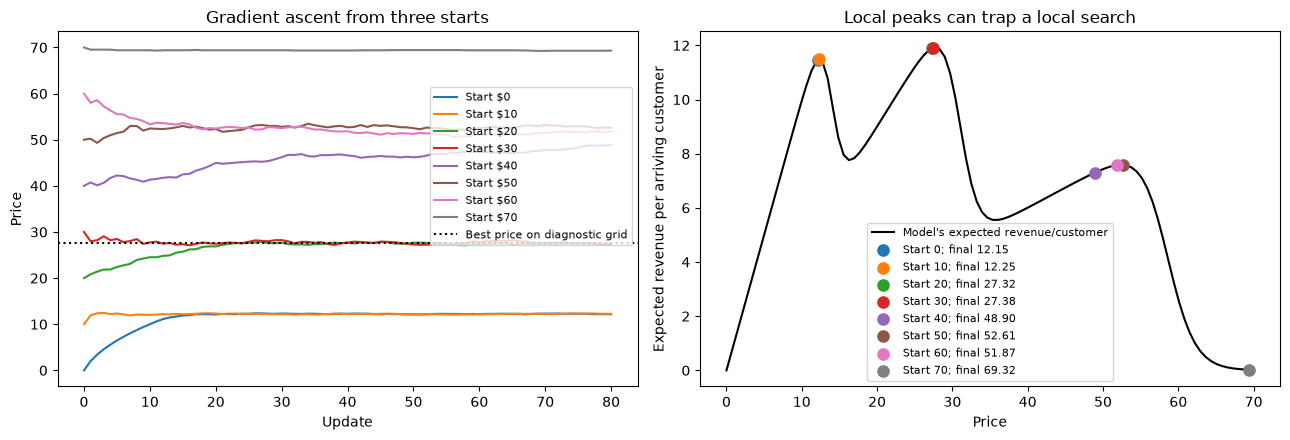

,start_price,final_price,search_customers,validation_customers,validation_revenue_per_customer,validation_se
0,0.0,12.153,47490,10036,11.499,0.027
1,10.0,12.249,48323,9894,11.453,0.030
2,20.0,27.321,48255,9826,11.773,0.136
3,30.0,27.379,47903,10105,11.854,0.135
4,40.0,48.902,48105,9800,7.275,0.176
5,50.0,52.611,47834,9875,7.464,0.185
6,60.0,51.869,47913,10164,7.640,0.182
7,70.0,69.325,48447,10042,0.007,0.007


In [10]:
# Only the diagnostic plot uses the model's true purchase curve.
# The search itself uses sales() at two nearby prices on every iteration.
starts = np.linspace(0,70,8)
ascent_paths = {
    start: gradient_ascent(start, seed=2026 + int(start))
    for start in starts
}
price_grid = np.linspace(0,70, 100)
expected_revenue_per_customer = price_grid * purchase_probability(price_grid)
grid_best_price = price_grid[np.argmax(expected_revenue_per_customer)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[1].plot(price_grid, expected_revenue_per_customer,
             color="black", label="Model's expected revenue/customer")
evaluation_rng = np.random.default_rng(9001)
summary = []
for index, (start, history) in enumerate(ascent_paths.items()):
    color = f"C{index}"
    prices = np.r_[start, history["next_price"].to_numpy()]
    final_price = prices[-1]
    axes[0].plot(np.arange(len(prices)), prices,
                 color=color, label=f"Start ${start:g}")
    axes[1].scatter(final_price, final_price * purchase_probability(final_price),
                    color=color, s=65, zorder=3,
                    label=f"Start {start:g}; final {final_price:.2f}")

    # Evaluate the selected price with fresh customers, outside the search data.
    validation = final_price * sales(final_price, mean_customers=10_000,
                                      rng=evaluation_rng)
    summary.append({
        "start_price": start,
        "final_price": final_price,
        "search_customers": int(history["customers"].sum()),
        "validation_customers": len(validation),
        "validation_revenue_per_customer": validation.mean(),
        "validation_se": validation.std(ddof=1) / np.sqrt(len(validation)),
    })
total_search = sum(r["search_customers"] for r in summary)
total_validation = sum(r["validation_customers"] for r in summary)
total_customers = total_search + total_validation
best_run = max(summary, key=lambda r: r["validation_revenue_per_customer"])
final_price = best_run["final_price"]
final_choices = sales(final_price, mean_customers=20_000, rng=evaluation_rng)
final_estimate = final_price * final_choices.mean()
total_customers += len(final_choices)
print(f"Final tested price: ${final_price:.2f}")
print(f"Estimated revenue per consumer: ${final_estimate:.3f}")
print(f"Percent of $11.925 benchmark: {100 * final_estimate / 11.925:.1f}%")
print(f"Total consumers experimented on: {total_customers}")
axes[0].axhline(grid_best_price, color="black", linestyle=":",
                label="Best price on diagnostic grid")
axes[0].set(xlabel="Update", ylabel="Price", title="Gradient ascent from three starts")
axes[1].set(xlabel="Price", ylabel="Expected revenue per arriving customer",
            title="Local peaks can trap a local search")
axes[0].legend(loc="center right", bbox_to_anchor=(1, 0.62), fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

pd.DataFrame(summary).round(3)